<a href="https://colab.research.google.com/github/lonerkou/ai/blob/main/1.Gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

各個疊代步驟的 x 位置：
[5.00000000e+00 2.00000000e+00 8.00000000e-01 3.20000000e-01
 1.28000000e-01 5.12000000e-02 2.04800000e-02 8.19200000e-03
 3.27680000e-03 1.31072000e-03 5.24288000e-04 2.09715200e-04
 8.38860800e-05 3.35544320e-05 1.34217728e-05 5.36870912e-06]


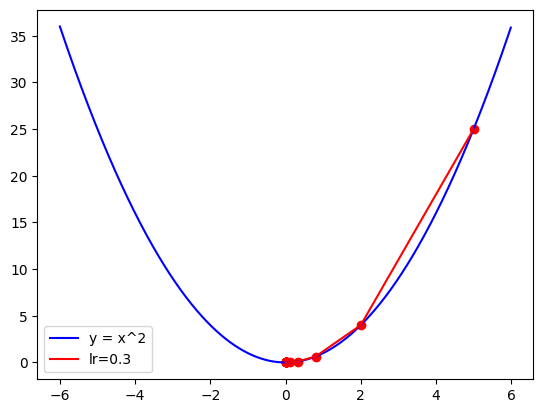

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 定義目標函數與其導數
# ==========================================

# 目標函數：y = x^2 (我們想找這個函數的最低點)
def func(x):
    return np.square(x)

# 目標函數的一階導數（梯度）：dy/dx = 2*x
# 導數代表當前位置的斜率，正數代表向右上升、負數代表向左上升
def dfunc(x):
    return 2 * x


# ==========================================
# 2. 定義梯度下降法 (Gradient Descent) 核心演算法
# ==========================================
def GD(x_start, df, epochs, lr):
    """
    梯度下降法。給定起始點與目標函數的一階導函數，求在 epochs 次疊代中 x 的更新值
        :param x_start: x 的起始點（初始權重）
        :param df: 目標函數的一階導函數
        :param epochs: 疊代次數（訓練週期）
        :param lr: 學習率（決定每次跨出步伐的大小）
        :return: x 在每次疊代後的位置紀錄（包括起始點），長度為 epochs + 1
    """
    # 建立一個陣列來儲存每次疊代後 x 的位置
    xs = np.zeros(epochs + 1)
    x = x_start
    xs[0] = x  # 記錄起始位置

    # 開始進行疊代更新
    for i in range(epochs):
        # 1. 計算當前位置的梯度（斜率）
        dx = df(x)

        # 2. 計算 x 要改變的幅度（v = - 梯度 × 學習率）
        # 負號代表「朝著斜率相反的方向」移動，以逼近最小值
        v = - dx * lr

        # 3. 更新 x 的位置
        x += v

        # 4. 記錄更新後的位置
        xs[i+1] = x

    return xs


# ==========================================
# 3. 主程式 (Main) 與超參數設定
# ==========================================

# 起始權重（從 x = 5 開始搜尋最小值）
x_start = 5

# 執行週期數（總共疊代 15 次）
epochs = 15

# 學習率（步長設為 0.3，控制步伐大小）
lr = 0.3

# 執行梯度下降法，計算出每次疊代的 x 座標序列
x = GD(x_start, dfunc, epochs, lr=lr)

# 印出每次疊代後的 x 位置數據
print("各個疊代步驟的 x 位置：")
print(x)

color = 'r'  # 設定繪圖顏色為紅色 ('r' = red)
from numpy import arange

# 建立畫布的自變數 x 範圍：從 -6.0 到 6.0，間距 0.01
t = arange(-6.0, 6.0, 0.01)

# 繪製藍色的目標函數拋物線 (y = x^2)
plt.plot(t, func(t), c='b', label='y = x^2')

# 繪製梯度下降過程中的路徑折線圖（紅線）
plt.plot(x, func(x), c=color, label='lr={}'.format(lr))

# 在每個疊代點上加上紅色散佈圖標記（紅點）
plt.scatter(x, func(x), c=color)

# 顯示圖例
plt.legend()

# 顯示繪製好的圖表
plt.show()